# 12-2. d별 성능 비교 (auto_arima)

6개 변수에서 d=0, 1, 2를 CRPS(`crps_ensemble`), MSE, 커버리지로 비교한다. **결정이 아니라 확인용**이고, `12-1`과 충돌해도 덮어쓰지 않는다.

- **모델**: `auto_arima`(d 고정, AICc, p,q ≤ 3, 절편 `"auto"`), 각 origin의 훈련 데이터만 사용
- **평가**: origin 20분기부터 시작해 앞 15개를 뺀 나머지(X3_l1은 22개)에서 h=1~4를 채점, 지표는 `var_std`로 정규화
- d를 바꿔도 예측을 수준 y로 되돌려 비교하므로 지표를 비교할 수 있다.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import os
import numpy as np
import pandas as pd
import pmdarima as pm
import properscoring as ps
import matplotlib.pyplot as plt
from scipy import stats
plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

raw = pd.read_csv("../../data/gold/gold_major_variables.csv")
raw = raw[raw["quarter"].notna()].reset_index(drop=True)
VARS = ["X3_l1", "X6_l1", "X2", "X1_l1", "X5_l1", "X4"]
DATA = {c: raw[["quarter", c]].dropna().reset_index(drop=True) for c in VARS}
H, MIN_TRAIN, INITIAL_CALIB, ALPHA, N_ENS = 4, 20, 15, 0.10, 500
Z = stats.norm.ppf(1 - ALPHA / 2)
U = stats.norm.ppf((np.arange(N_ENS) + 0.5) / N_ENS)
CACHE = "../cache/cache_132_d_compare_df.pkl"


def run(c, d):
    v = DATA[c][c].values.astype(float)
    vs = v.std()
    rows = []
    for o in list(range(MIN_TRAIN, len(v) - H + 1))[INITIAL_CALIB:]:
        train, actual = v[:o], v[o:o + H]
        m = pm.auto_arima(train, d=d, seasonal=False, information_criterion="aicc", max_p=3, max_q=3, suppress_warnings=True, error_action="ignore")
        fc, conf = m.predict(n_periods=H, return_conf_int=True, alpha=ALPHA)
        fc = np.asarray(fc)
        sig = np.maximum((conf[:, 1] - conf[:, 0]) / (2 * Z), 1e-6)
        crps = ps.crps_ensemble(actual, fc[:, None] + sig[:, None] * U[None, :]) / vs
        for h in range(H):
            rows.append({"변수": c, "d": d, "origin": o, "h": h + 1, "order": str(m.order), "적중": float(conf[h, 0] <= actual[h] <= conf[h, 1]) * 100,
                         "MSE": ((actual[h] - fc[h]) / vs) ** 2, "CRPS": crps[h], "폭": (conf[h, 1] - conf[h, 0]) / vs})
    return pd.DataFrame(rows)


if os.path.exists(CACHE):
    R = pd.read_pickle(CACHE)
else:
    R = pd.concat([run(c, d) for c in VARS for d in (0, 1, 2)], ignore_index=True)
    R.to_pickle(CACHE)
print(len(R), "행,", R.groupby("변수")["origin"].nunique().to_dict())

1596 행, {'X1_l1': 21, 'X2': 22, 'X3_l1': 22, 'X4': 22, 'X5_l1': 21, 'X6_l1': 25}


## 1. 재현 확인

`X3_l1`의 d=0, 1, 2가 `9-1`의 커버리지·MSE, `11-1`의 CRPS와 같은지 본다.

In [2]:
old = pd.read_pickle("../cache/cache_91_fixed_d_q7_df.pkl")          # 9-1 (d, origin) 별 커버리지, MSE
mx_cov = mx_mse = 0.0
for d in (0, 1, 2):
    new = R[(R["변수"] == "X3_l1") & (R["d"] == d)].groupby("origin")[["적중", "MSE"]].mean()
    o_ = old.loc[d]
    mx_cov = max(mx_cov, float((new["적중"] - o_["커버리지"]).abs().max()))
    mx_mse = max(mx_mse, float((new["MSE"] - o_["MSE"]).abs().max()))
print(f"9-1과의 최대 차이 -- 커버리지 {mx_cov:.2e}, MSE {mx_mse:.2e}")
r11 = pd.read_pickle("../cache/cache_107_rank_compare_df.pkl")
r11 = r11[(r11["모델"] == "auto_arima") & (r11["스케일"] == "원") & (r11["구간"] == "자체")]
new1 = R[(R["변수"] == "X3_l1") & (R["d"] == 1)]
print(f"d=1 CRPS: 12-2 {new1['CRPS'].mean():.4f} / 11-1 {r11['crps_ensemble'].mean():.4f} (11-1은 p,q 상한이 기본값 5)")

9-1과의 최대 차이 -- 커버리지 0.00e+00, MSE 1.78e-15
d=1 CRPS: 12-2 0.6104 / 11-1 0.6104 (11-1은 p,q 상한이 기본값 5)


## 2. 변수별 d=0, 1, 2

예측 84~100개의 평균이다. 커버리지는 90%에 가까울수록, 나머지는 낮을수록 좋다.

In [3]:
g = R.groupby(["변수", "d"]).agg(커버리지=("적중", "mean"), MSE=("MSE", "mean"), CRPS=("CRPS", "mean"), 폭=("폭", "mean"))
g = g.reindex(VARS, level=0)
display(g.round(3))

커버리지     MSE   CRPS      폭
변수    d                              
X3_l1 0  50.000   1.269  0.668  1.454
      1  61.364   1.164  0.610  1.705
      2  43.182   2.495  0.929  2.088
X6_l1 0  80.000   0.326  0.326  1.321
      1  85.000   0.243  0.275  1.448
      2  86.000   0.249  0.283  1.636
X2    0  77.273   0.966  0.538  2.173
      1  80.682   1.200  0.585  2.795
      2  90.909   2.544  0.802  4.927
X1_l1 0  69.048   1.492  0.726  3.030
      1  75.000   2.879  0.989  4.979
      2  73.810  10.771  1.817  8.323
X5_l1 0  78.571   2.201  0.809  2.759
      1  77.381   2.855  0.937  3.519
      2  65.476  12.128  1.845  4.995
X4    0  63.636   1.049  0.609  1.968
      1  71.591   1.182  0.625  2.630
      2  72.727   1.398  0.682  3.001

In [4]:
rows = []
for c in VARS:
    a, b = g.loc[(c, 0)], g.loc[(c, 1)]
    o = R[R["변수"] == c].groupby(["d", "origin"])[["MSE", "CRPS"]].mean()
    n_o = len(o.loc[1])
    rows.append({"변수": c, "origin 수": n_o,
                 "MSE d=0 / d=1": a["MSE"] / b["MSE"], "CRPS d=0 / d=1": a["CRPS"] / b["CRPS"], "커버리지 d=0 - d=1(%p)": a["커버리지"] - b["커버리지"],
                 "d=1이 더 좋은 origin(MSE)": f"{int((o.loc[1, 'MSE'] < o.loc[0, 'MSE']).sum())}/{n_o}", "d=1이 더 좋은 origin(CRPS)": f"{int((o.loc[1, 'CRPS'] < o.loc[0, 'CRPS']).sum())}/{n_o}"})
S = pd.DataFrame(rows).set_index("변수")
display(S.round(3))
print("비율이 1보다 작으면 d=0이 더 좋다.")

,origin 수,MSE d=0 / d=1,CRPS d=0 / d=1,커버리지 d=0 - d=1(%p),d=1이 더 좋은 origin(MSE),d=1이 더 좋은 origin(CRPS)
변수,,,,,,
X3_l1,22,1.091,1.095,-11.364,12/22,13/22
X6_l1,25,1.341,1.183,-5.000,21/25,21/25
X2,22,0.806,0.920,-3.409,8/22,11/22
X1_l1,21,0.518,0.735,-5.952,8/21,5/21
X5_l1,21,0.771,0.864,1.190,6/21,0/21
X4,22,0.888,0.974,-7.955,9/22,11/22


비율이 1보다 작으면 d=0이 더 좋다.


## 3. h=1과 h=4

d=0과 d=1의 차이가 어느 예측 단계에서 나는지 본다.

In [5]:
hh = R[R["d"].isin([0, 1])].groupby(["변수", "h", "d"])[["MSE", "CRPS"]].mean().unstack("d")
rows = []
for c in VARS:
    r = {"변수": c}
    for h in (1, 4):
        r[f"MSE h={h} (d=0 / d=1)"] = hh.loc[(c, h), ("MSE", 0)] / hh.loc[(c, h), ("MSE", 1)]
        r[f"CRPS h={h} (d=0 / d=1)"] = hh.loc[(c, h), ("CRPS", 0)] / hh.loc[(c, h), ("CRPS", 1)]
    rows.append(r)
display(pd.DataFrame(rows).set_index("변수").round(3))
print("비율이 1보다 작으면 d=0이 더 좋다.")

,MSE h=1 (d=0 / d=1),CRPS h=1 (d=0 / d=1),MSE h=4 (d=0 / d=1),CRPS h=4 (d=0 / d=1)
변수,,,,
X3_l1,1.061,1.034,1.123,1.140
X6_l1,1.099,1.053,1.499,1.286
X2,0.957,0.988,0.723,0.848
X1_l1,0.720,0.861,0.400,0.626
X5_l1,0.941,0.976,0.645,0.763
X4,0.903,0.929,0.866,0.985


비율이 1보다 작으면 d=0이 더 좋다.


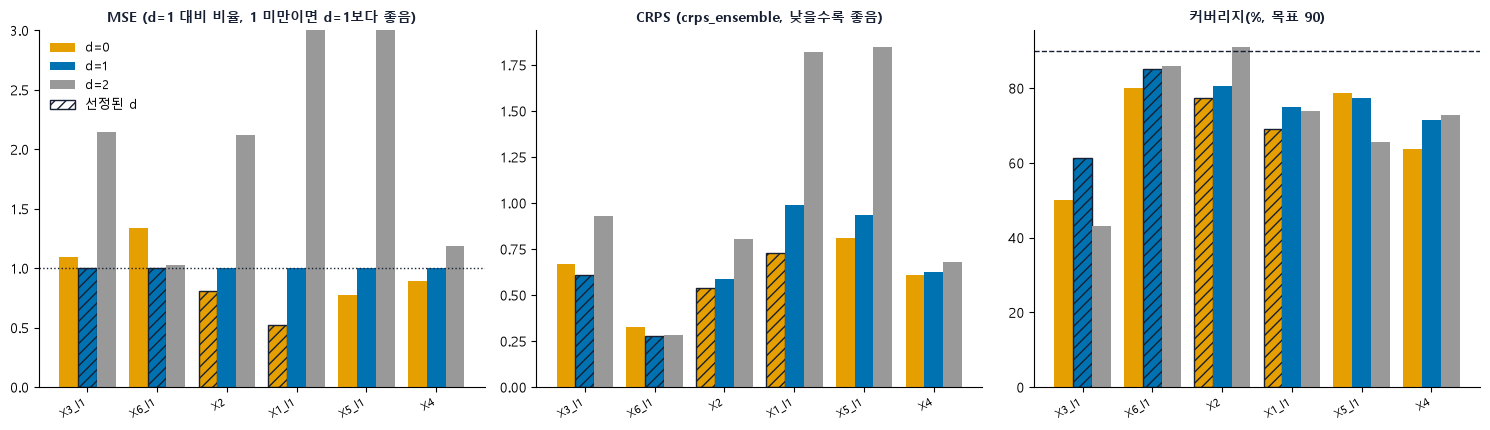

In [6]:
CHOSEN = {"X3_l1": 1, "X6_l1": 1, "X2": 0, "X1_l1": 0}      # 12-1의 판정 (애매한 2개 변수 제외)
fig, axes = plt.subplots(1, 3, figsize=(15, 4.4))
col = {0: "#E69F00", 1: "#0072B2", 2: "#999999"}
x = np.arange(len(VARS))
for ax, (m, ttl) in zip(axes, [("MSE", "MSE (d=1 대비 비율, 1 미만이면 d=1보다 좋음)"), ("CRPS", "CRPS (crps_ensemble, 낮을수록 좋음)"), ("커버리지", "커버리지(%, 목표 90)")]):
    for k, d in enumerate((0, 1, 2)):
        v = [g.loc[(c, d), m] / (g.loc[(c, 1), m] if m == "MSE" else 1) for c in VARS]      # MSE만 d=1 대비 비율, CRPS와 커버리지는 값 그대로
        bars = ax.bar(x + (k - 1) * 0.27, v, 0.27, color=col[d], label=f"d={d}")
        for b, c in zip(bars, VARS):
            if CHOSEN.get(c) == d:                       # 12-1에서 정한 d에 빗금 (애매한 변수는 표시 안 함)
                b.set_hatch("///")
                b.set_edgecolor("#172033")
    if m == "커버리지":
        ax.axhline(90, color="#172033", linestyle="--", linewidth=1)
    elif m == "MSE":
        ax.axhline(1, color="#172033", linestyle=":", linewidth=1)
        ax.set_ylim(0, 3)
    ax.set_xticks(x)
    ax.set_xticklabels(VARS, rotation=30, ha="right", fontsize=8)
    ax.set_title(ttl, fontsize=10, fontweight="bold", color="#172033")
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
from matplotlib.patches import Patch
handles = [Patch(facecolor=col[d], label=f"d={d}") for d in (0, 1, 2)] + [Patch(facecolor="white", edgecolor="#172033", hatch="///", label="선정된 d")]
axes[0].legend(handles=handles, frameon=False, fontsize=9)
fig.tight_layout()
plt.show()

## 4. 결론 (확인용)

**성능은 `12-1`의 판정과 같은 방향이다.** `X3_l1`은 `9-1`, `11-1`을 그대로 재현한다.

| 변수 | 12-1 판정 | MSE d=0/d=1 | CRPS d=0/d=1 | 성능 방향 |
|---|---|---|---|---|
| X3_l1 | d=1 | 1.091 | 1.095 | d=1 (9~10% 차이, 근소) |
| X6_l1 | d=1 | 1.341 | 1.183 | d=1 (18~34% 차이) |
| X2 | d=0 | 0.806 | 0.920 | d=0 |
| X1_l1 | d=0 | 0.518 | 0.735 | d=0 (d=1이 MSE 2배) |
| X5_l1 | 애매 | 0.771 | 0.864 | d=0 (21/21 origin) |
| X4 | 애매 | 0.888 | 0.974 | d=0 쪽이나 약함 |

- **충돌은 없다.** d=1·d=0이 분명한 4개 변수는 성능도 같은 쪽이다.
- **d=2는 거의 항상 가장 나쁘다.**
- **차이는 h=4에서 크고 h=1은 거의 같다.**
- **한계**: 확인용이고, origin이 겹치며 유의성 검정은 하지 않았다.